# Import Libraries & Dataset

In [1]:
import pandas as pd
from PIL import Image
import os
import xml.etree.ElementTree as ET
import random
import matplotlib.pyplot as plt
import seaborn as sns
import cv2

In [2]:
for dirname, _, filenames in os.walk('/kaggle/input'):
    print(dirname)

/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/gopalbhattrai
/kaggle/input/datasets/gopalbhattrai/pascal-voc-2012-dataset
/kaggle/input/datasets/gopalbhattrai/pascal-voc-2012-dataset/VOC2012_test
/kaggle/input/datasets/gopalbhattrai/pascal-voc-2012-dataset/VOC2012_test/VOC2012_test
/kaggle/input/datasets/gopalbhattrai/pascal-voc-2012-dataset/VOC2012_test/VOC2012_test/Annotations
/kaggle/input/datasets/gopalbhattrai/pascal-voc-2012-dataset/VOC2012_test/VOC2012_test/ImageSets
/kaggle/input/datasets/gopalbhattrai/pascal-voc-2012-dataset/VOC2012_test/VOC2012_test/ImageSets/Action
/kaggle/input/datasets/gopalbhattrai/pascal-voc-2012-dataset/VOC2012_test/VOC2012_test/ImageSets/Layout
/kaggle/input/datasets/gopalbhattrai/pascal-voc-2012-dataset/VOC2012_test/VOC2012_test/ImageSets/Main
/kaggle/input/datasets/gopalbhattrai/pascal-voc-2012-dataset/VOC2012_test/VOC2012_test/ImageSets/Segmentation
/kaggle/input/datasets/gopalbhattrai/pascal-voc-2012-dataset/VOC2012_test/VOC2012_test/J

In [3]:
DATASET_PATH = "/kaggle/input/datasets/gopalbhattrai/pascal-voc-2012-dataset/VOC2012_train_val/VOC2012_train_val"

IMAGE_PATH = os.path.join(DATASET_PATH, "JPEGImages")
ANNOTATION_PATH = os.path.join(DATASET_PATH, "Annotations")

print("Images folder exists:", os.path.exists(IMAGE_PATH))
print("Annotations folder exists:", os.path.exists(ANNOTATION_PATH))

Images folder exists: True
Annotations folder exists: True


# EDA

## Dataset Overview

In [4]:
image_files = [
    f for f in os.listdir(IMAGE_PATH)
    if f.lower().endswith(('.jpg', '.jpeg', '.png'))
]

annotation_files = [
    f for f in os.listdir(ANNOTATION_PATH)
    if f.endswith('.xml')
]

print("Total Images:", len(image_files))
print("Total Annotation Files:", len(annotation_files))

print("\nSample Image Files:")
print(image_files[:10])

print("\nSample Annotation Files:")
print(annotation_files[:10])

Total Images: 17125
Total Annotation Files: 17125

Sample Image Files:
['2007_000027.jpg', '2007_000032.jpg', '2007_000033.jpg', '2007_000039.jpg', '2007_000042.jpg', '2007_000061.jpg', '2007_000063.jpg', '2007_000068.jpg', '2007_000121.jpg', '2007_000123.jpg']

Sample Annotation Files:
['2007_000027.xml', '2007_000032.xml', '2007_000033.xml', '2007_000039.xml', '2007_000042.xml', '2007_000061.xml', '2007_000063.xml', '2007_000068.xml', '2007_000121.xml', '2007_000123.xml']


Does every image has a corresponding annotation?

In [5]:
image_ids = {os.path.splitext(f)[0] for f in image_files}
annotation_ids = {os.path.splitext(f)[0] for f in annotation_files}

print("Images with annotations:", len(image_ids & annotation_ids))
print("Images without annotations:", len(image_ids - annotation_ids))
print("Annotations without images:", len(annotation_ids - image_ids))

Images with annotations: 17125
Images without annotations: 0
Annotations without images: 0


In [6]:
print(image_files[:5])
print(type(image_files))

['2007_000027.jpg', '2007_000032.jpg', '2007_000033.jpg', '2007_000039.jpg', '2007_000042.jpg']
<class 'list'>


## Image Dimensions Analysis

In [7]:
image_data = []

for file in image_files:

    img_path = os.path.join(IMAGE_PATH, file)

    img = Image.open(img_path)

    width, height = img.size

    image_data.append({
        'filename': file,
        'width': width,
        'height': height,
        'format': img.format,
        'mode': img.mode,
        'aspect_ratio': width / height
    })

image_df = pd.DataFrame(image_data)

image_df.head()

,filename,width,height,format,mode,aspect_ratio
0,2007_000027.jpg,486,500,JPEG,RGB,0.972000
1,2007_000032.jpg,500,281,JPEG,RGB,1.779359
2,2007_000033.jpg,500,366,JPEG,RGB,1.366120
3,2007_000039.jpg,500,375,JPEG,RGB,1.333333
4,2007_000042.jpg,500,335,JPEG,RGB,1.492537


Statistical summary

In [8]:
image_df.describe().T

,count,mean,std,min,25%,50%,75%,max
width,17125.0,466.797547,61.931367,142.000,499.00000,500.000000,500.000000,500.000000
height,17125.0,389.507620,65.497125,71.000,338.00000,375.000000,400.000000,500.000000
aspect_ratio,17125.0,1.248242,0.316874,0.284,1.22549,1.333333,1.428571,7.042254


Visualize image dimensions

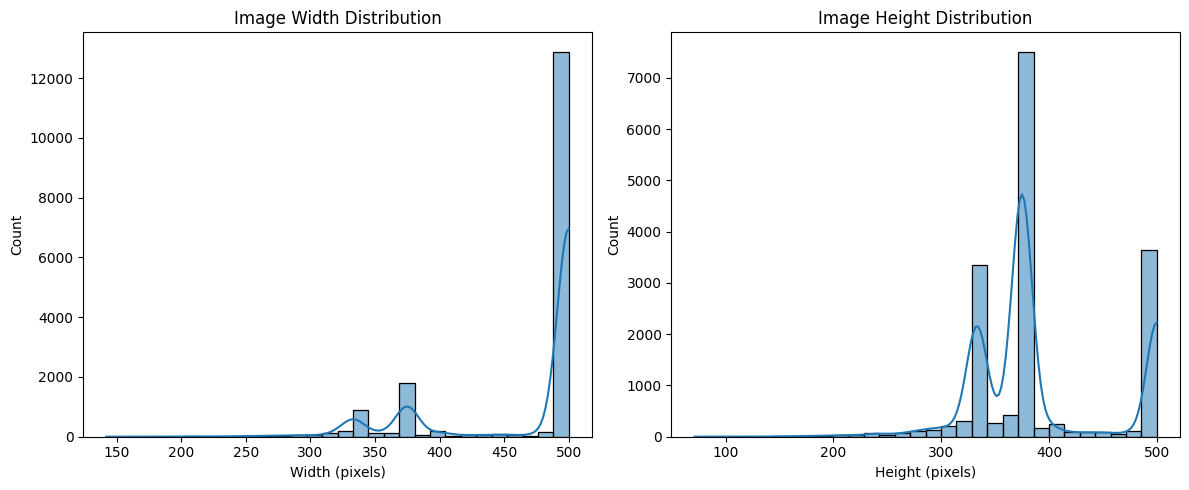

In [9]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(image_df['width'], bins=30, kde=True)
plt.title("Image Width Distribution")
plt.xlabel("Width (pixels)")

plt.subplot(1, 2, 2)
sns.histplot(image_df['height'], bins=30, kde=True)
plt.title("Image Height Distribution")
plt.xlabel("Height (pixels)")

plt.tight_layout()
plt.show()

Width vs. height

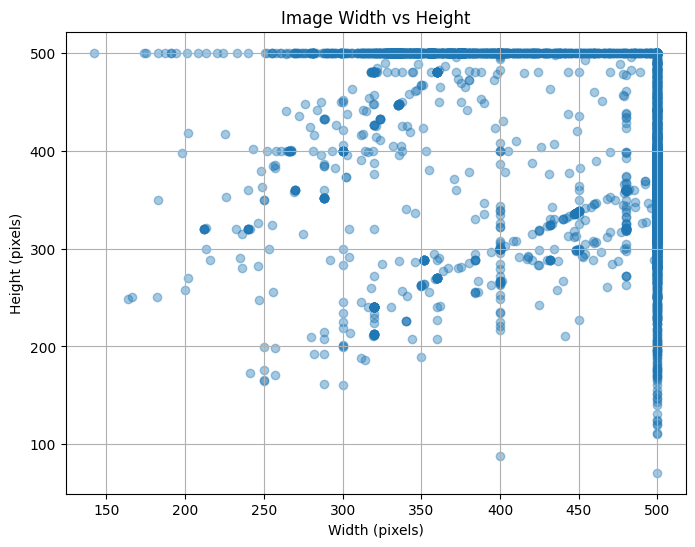

In [10]:
plt.figure(figsize=(8, 6))

plt.scatter(image_df['width'], image_df['height'], alpha=0.4)

plt.xlabel("Width (pixels)")
plt.ylabel("Height (pixels)")
plt.title("Image Width vs Height")

plt.grid()
plt.show()

Image formats and color channels

In [11]:
print("Image Formats:")
print(image_df['format'].value_counts())

print("\nImage Modes:")
print(image_df['mode'].value_counts())

Image Formats:
format
JPEG    17125
Name: count, dtype: int64

Image Modes:
mode
RGB    17125
Name: count, dtype: int64


random image samples

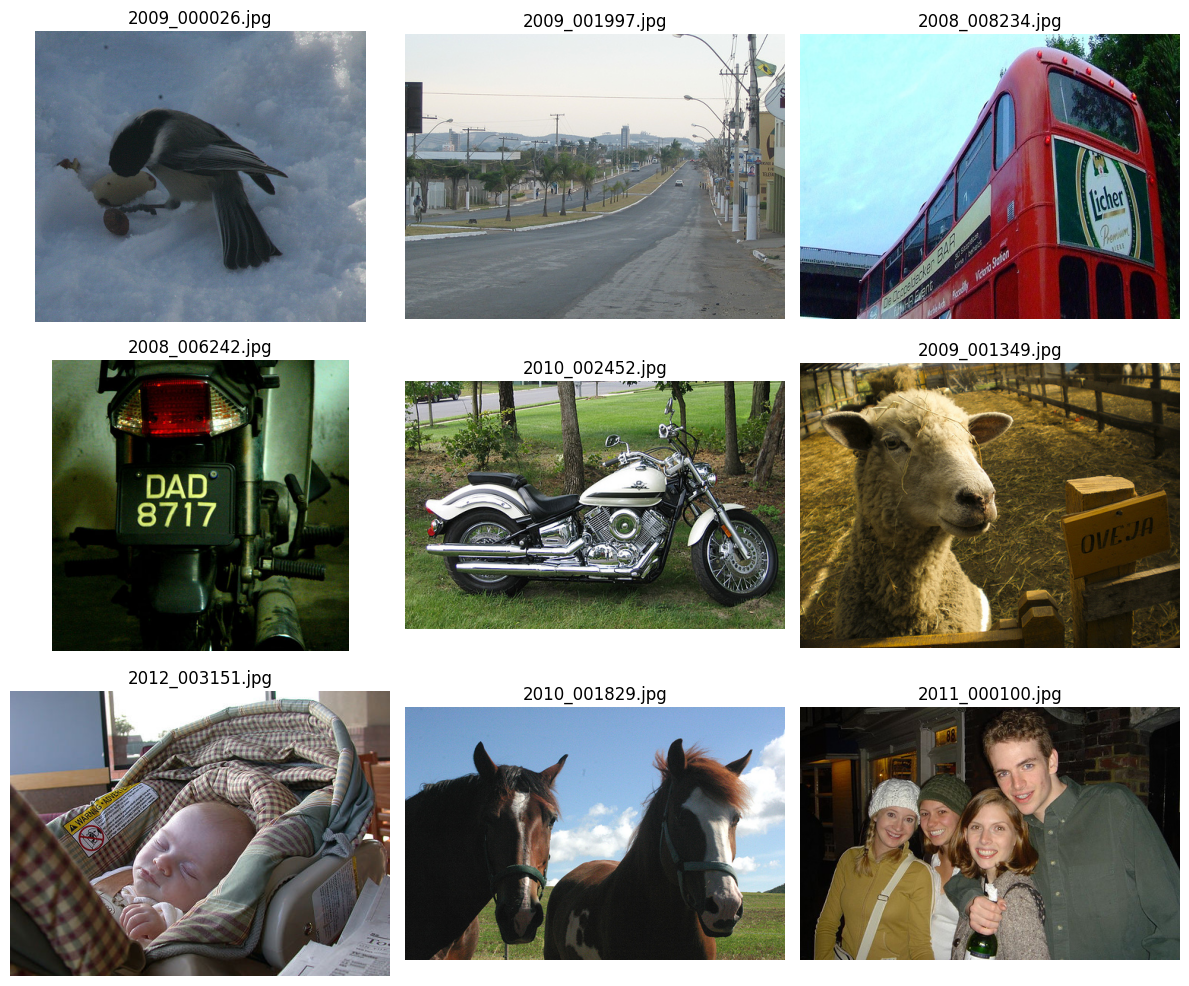

In [12]:
sample_images = random.sample(image_files, 9)

plt.figure(figsize=(12, 10))

for i, file in enumerate(sample_images):

    img_path = os.path.join(IMAGE_PATH, file)
    img = Image.open(img_path)

    plt.subplot(3, 3, i + 1)
    plt.imshow(img)
    plt.title(file)
    plt.axis('off')

plt.tight_layout()
plt.show()

## Analyze XML annotations

In [13]:
annotation_data = []

for file in annotation_files:

    xml_path = os.path.join(ANNOTATION_PATH, file)

    tree = ET.parse(xml_path)
    root = tree.getroot()

    filename = root.find('filename').text

    size = root.find('size')

    width = int(size.find('width').text)
    height = int(size.find('height').text)

    objects = root.findall('object')

    for obj in objects:

        class_name = obj.find('name').text

        bbox = obj.find('bndbox')

        xmin = float(bbox.find('xmin').text)
        ymin = float(bbox.find('ymin').text)
        xmax = float(bbox.find('xmax').text)
        ymax = float(bbox.find('ymax').text)

        annotation_data.append({
            'filename': filename,
            'class': class_name,
            'image_width': width,
            'image_height': height,
            'xmin': xmin,
            'ymin': ymin,
            'xmax': xmax,
            'ymax': ymax,
            'bbox_width': xmax - xmin,
            'bbox_height': ymax - ymin,
            'bbox_area': (xmax - xmin) * (ymax - ymin)
        })

annotation_df = pd.DataFrame(annotation_data)

display(annotation_df.head())

,filename,class,image_width,image_height,xmin,ymin,xmax,ymax,bbox_width,bbox_height,bbox_area
0,2007_000027.jpg,person,486,500,174.0,101.0,349.0,351.0,175.0,250.0,43750.0
1,2007_000032.jpg,aeroplane,500,281,104.0,78.0,375.0,183.0,271.0,105.0,28455.0
2,2007_000032.jpg,aeroplane,500,281,133.0,88.0,197.0,123.0,64.0,35.0,2240.0
3,2007_000032.jpg,person,500,281,195.0,180.0,213.0,229.0,18.0,49.0,882.0
4,2007_000032.jpg,person,500,281,26.0,189.0,44.0,238.0,18.0,49.0,882.0


### Object class distribution

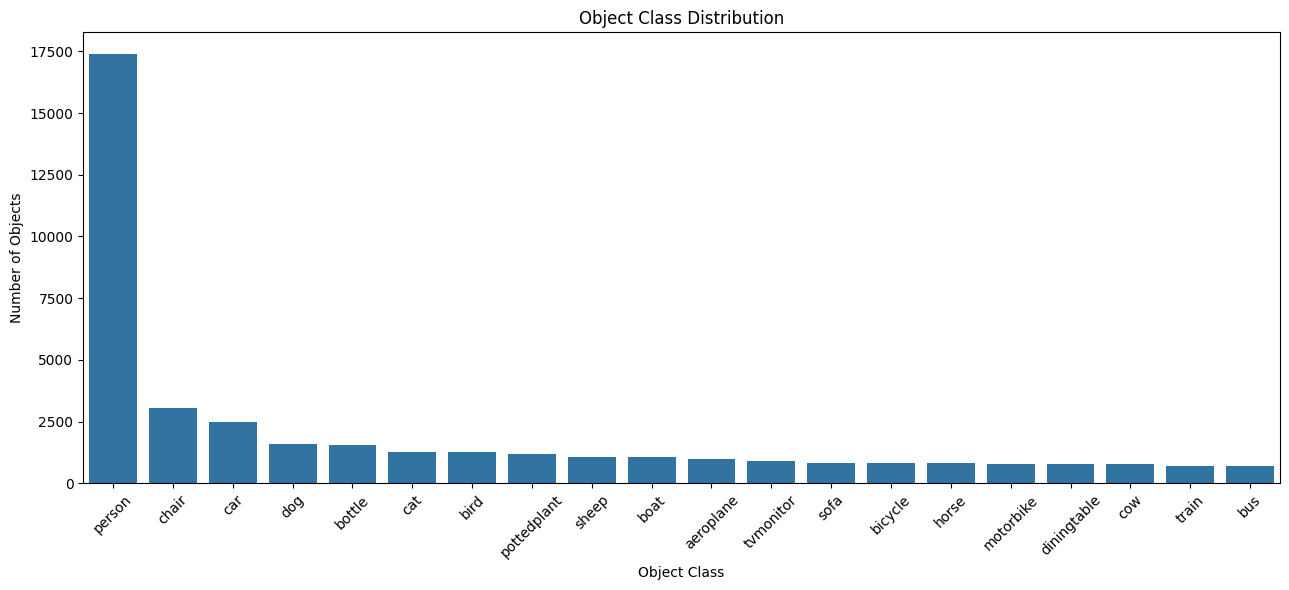

class
person         17401
chair           3056
car             2492
dog             1598
bottle          1561
cat             1277
bird            1271
pottedplant     1202
sheep           1084
boat            1059
aeroplane       1002
tvmonitor        893
sofa             841
bicycle          837
horse            803
motorbike        801
diningtable      800
cow              771
train            704
bus              685
Name: count, dtype: int64


In [14]:
class_counts = annotation_df['class'].value_counts()

plt.figure(figsize=(13, 6))

sns.barplot(
    x=class_counts.index,
    y=class_counts.values
)

plt.title("Object Class Distribution")
plt.xlabel("Object Class")
plt.ylabel("Number of Objects")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

print(class_counts)

Number of objects per image

In [15]:
objects_per_image = annotation_df.groupby('filename').size()

print("Average objects per annotated image:",
      objects_per_image.mean())

print("Maximum objects in one image:",
      objects_per_image.max())

print("Minimum objects in one annotated image:",
      objects_per_image.min())

Average objects per annotated image: 2.3438248175182483
Maximum objects in one image: 56
Minimum objects in one annotated image: 1


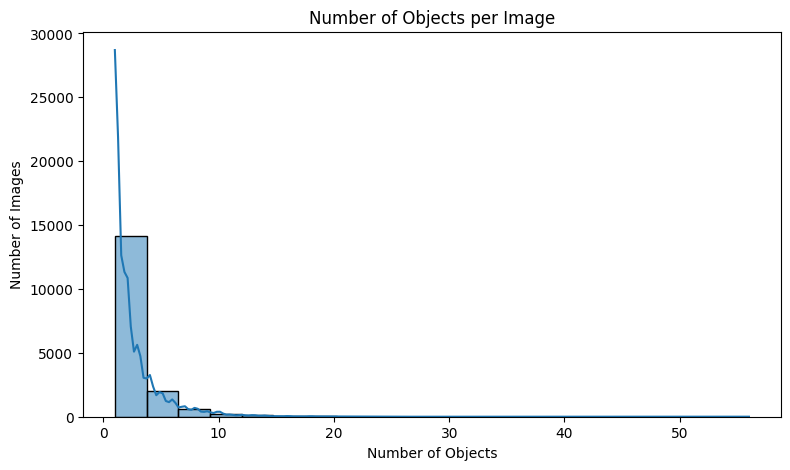

In [16]:
plt.figure(figsize=(9, 5))

sns.histplot(objects_per_image, bins=20, kde=True)

plt.title("Number of Objects per Image")
plt.xlabel("Number of Objects")
plt.ylabel("Number of Images")

plt.show()

### Bounding box analysis

In [17]:
annotation_df['bbox_width_ratio'] = (
    annotation_df['bbox_width'] / annotation_df['image_width']
)

annotation_df['bbox_height_ratio'] = (
    annotation_df['bbox_height'] / annotation_df['image_height']
)

annotation_df['bbox_area_ratio'] = (
    annotation_df['bbox_area'] /
    (annotation_df['image_width'] * annotation_df['image_height'])
)

display(
    annotation_df[
        ['bbox_width', 'bbox_height', 'bbox_area',
         'bbox_width_ratio', 'bbox_height_ratio',
         'bbox_area_ratio']
    ].describe().T
)

,count,mean,std,min,25%,50%,75%,max
bbox_width,40138.0,158.534207,130.942585,2.000000,54.000000,116.000,233.000000,499.000000
bbox_height,40138.0,173.275664,116.890182,4.000000,73.000000,153.000,257.000000,499.000000
bbox_area,40138.0,37342.469420,44537.842389,14.000000,4140.000000,18290.000,55375.750000,249001.000000
bbox_width_ratio,40138.0,0.340588,0.280220,0.004167,0.114000,0.248,0.508000,0.998000
bbox_height_ratio,40138.0,0.448953,0.286058,0.008000,0.194667,0.408,0.681682,0.998000
bbox_area_ratio,40138.0,0.208130,0.244880,0.000081,0.023185,0.103,0.311019,0.996004


Bounding box dimensions distribution

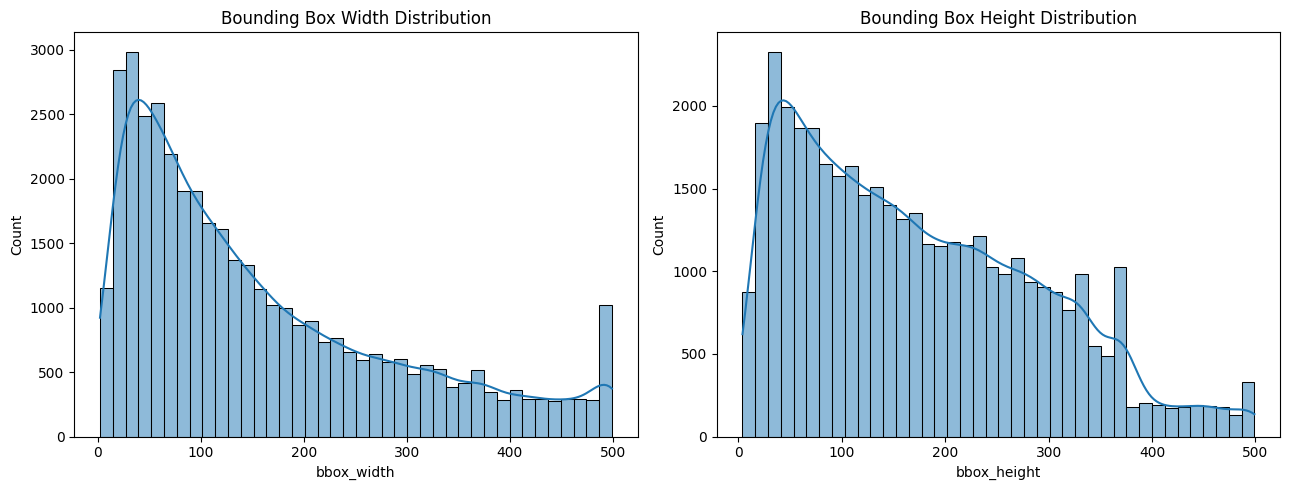

In [18]:
plt.figure(figsize=(13, 5))

plt.subplot(1, 2, 1)
sns.histplot(annotation_df['bbox_width'], bins=40, kde=True)
plt.title("Bounding Box Width Distribution")

plt.subplot(1, 2, 2)
sns.histplot(annotation_df['bbox_height'], bins=40, kde=True)
plt.title("Bounding Box Height Distribution")

plt.tight_layout()
plt.show()

Object relative area

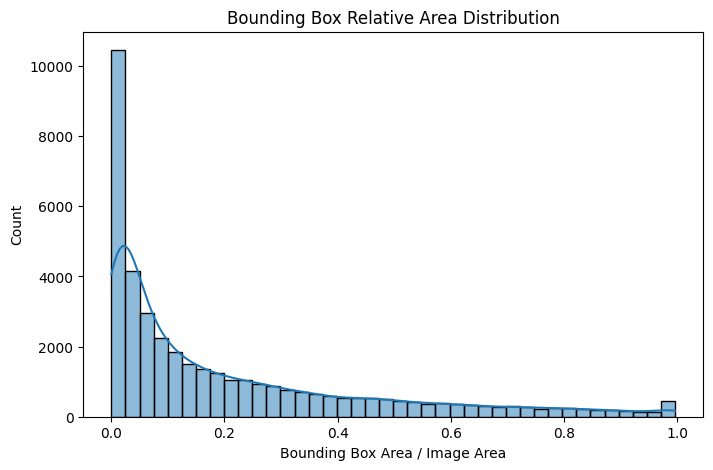

In [19]:
plt.figure(figsize=(8, 5))

sns.histplot(annotation_df['bbox_area_ratio'], bins=40, kde=True)

plt.title("Bounding Box Relative Area Distribution")
plt.xlabel("Bounding Box Area / Image Area")

plt.show()

Annotation quality

In [20]:
invalid_boxes = annotation_df[
    (annotation_df['xmin'] >= annotation_df['xmax']) |
    (annotation_df['ymin'] >= annotation_df['ymax']) |
    (annotation_df['xmin'] < 0) |
    (annotation_df['ymin'] < 0) |
    (annotation_df['xmax'] > annotation_df['image_width']) |
    (annotation_df['ymax'] > annotation_df['image_height'])
]

print("Total bounding boxes:", len(annotation_df))
print("Invalid bounding boxes:", len(invalid_boxes))

Total bounding boxes: 40138
Invalid bounding boxes: 0


In [21]:
annotated_image_ids = set(annotation_df['filename'])

empty_annotations = []

for file in annotation_files:

    xml_path = os.path.join(ANNOTATION_PATH, file)

    root = ET.parse(xml_path).getroot()

    if len(root.findall('object')) == 0:
        empty_annotations.append(file)

print("Images with zero objects:", len(empty_annotations))

Images with zero objects: 0


## Visualize bounding boxes on sample images

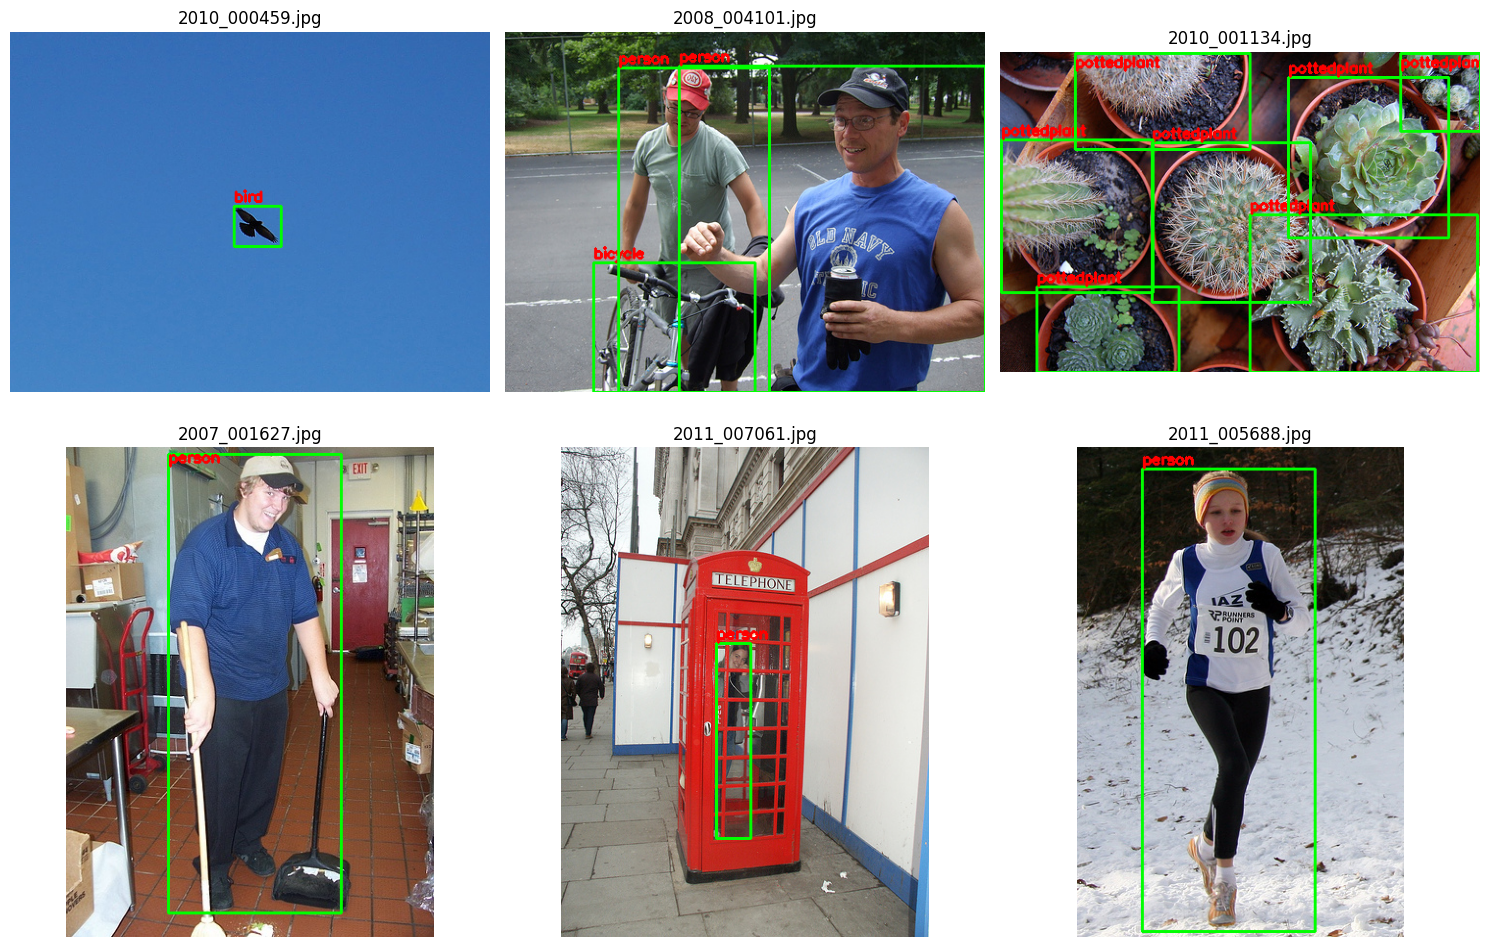

In [22]:
sample_files = random.sample(annotation_files, 6)

plt.figure(figsize=(15, 10))

for i, file in enumerate(sample_files):

    xml_path = os.path.join(ANNOTATION_PATH, file)

    root = ET.parse(xml_path).getroot()

    filename = root.find('filename').text

    img_path = os.path.join(IMAGE_PATH, filename)

    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    for obj in root.findall('object'):

        name = obj.find('name').text
        bbox = obj.find('bndbox')

        xmin = int(float(bbox.find('xmin').text))
        ymin = int(float(bbox.find('ymin').text))
        xmax = int(float(bbox.find('xmax').text))
        ymax = int(float(bbox.find('ymax').text))

        cv2.rectangle(img, (xmin, ymin), (xmax, ymax),
                      (0, 255, 0), 2)

        cv2.putText(img, name, (xmin, max(ymin - 5, 15)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5,
                    (255, 0, 0), 2)

    plt.subplot(2, 3, i + 1)
    plt.imshow(img)
    plt.title(filename)
    plt.axis('off')

plt.tight_layout()
plt.show()

# Dataset Summary

In [23]:
print("=" * 50)
print("PASCAL VOC 2012 - DATASET EDA SUMMARY")
print("=" * 50)

print(f"\nTotal Images: {len(image_df)}")
print(f"Total XML Annotations: {len(annotation_files)}")
print(f"Total Annotated Objects: {len(annotation_df)}")

print("\nIMAGE DIMENSIONS")
print(f"Minimum Width: {image_df['width'].min()}")
print(f"Maximum Width: {image_df['width'].max()}")
print(f"Average Width: {image_df['width'].mean():.2f}")

print(f"Minimum Height: {image_df['height'].min()}")
print(f"Maximum Height: {image_df['height'].max()}")
print(f"Average Height: {image_df['height'].mean():.2f}")

print("\nOBJECT STATISTICS")
print(f"Number of Classes: {annotation_df['class'].nunique()}")
print(f"Average Objects per Image: {objects_per_image.mean():.2f}")
print(f"Maximum Objects per Image: {objects_per_image.max()}")

print("\nANNOTATION QUALITY")
print(f"Invalid Bounding Boxes: {len(invalid_boxes)}")
print(f"Images with No Objects: {len(empty_annotations)}")

print("\nCLASS DISTRIBUTION")
print(class_counts)

print("=" * 50)

PASCAL VOC 2012 - DATASET EDA SUMMARY

Total Images: 17125
Total XML Annotations: 17125
Total Annotated Objects: 40138

IMAGE DIMENSIONS
Minimum Width: 142
Maximum Width: 500
Average Width: 466.80
Minimum Height: 71
Maximum Height: 500
Average Height: 389.51

OBJECT STATISTICS
Number of Classes: 20
Average Objects per Image: 2.34
Maximum Objects per Image: 56

ANNOTATION QUALITY
Invalid Bounding Boxes: 0
Images with No Objects: 0

CLASS DISTRIBUTION
class
person         17401
chair           3056
car             2492
dog             1598
bottle          1561
cat             1277
bird            1271
pottedplant     1202
sheep           1084
boat            1059
aeroplane       1002
tvmonitor        893
sofa             841
bicycle          837
horse            803
motorbike        801
diningtable      800
cow              771
train            704
bus              685
Name: count, dtype: int64
